# 01 · The Address Is the Identity

**NHyDB 0.27.1 notebook series · v1**

Why every storage cell of NHyDB **is** exactly one natural number – and why two cells can never share one. Almost no database code yet: this notebook is about the mathematics that everything else is built on.

> **Who is this for?** This notebook starts with a short introduction and continues with runnable examples. **New to NHyDB?** Read from top to bottom – every idea is introduced before it is used. **Already know the basics?** Skip the sections marked 📘 *Background* and jump to the experiments marked ▶. All cells run from top to bottom; optional deep dives are marked ⏩ *Advanced*.

**What you will learn**

* how a cell `(u, v, lane)` becomes a number `N` – and how `N` turns back into the cell
* what the **groups** `G`, the two **lanes** NL/NR and the boundary points **GZ** and **N0** are
* why the numbering is **collision-free**: every natural number has exactly one place
* how to explore any number yourself with `explore_n(N)`

**Recommended before:** [00 · Welcome](00_start_here_v1.ipynb) (optional).

### Setup

The next cell checks the environment and defines a few small plotting helpers used in
this notebook. It is collapsed because it is not about NHyDB itself – feel free to open
it. Every database in this notebook lives in a temporary folder that is removed at
the end.

In [1]:
import math
import os
import shutil
import sys
import tempfile

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle

import nhydb

# --- environment check ---------------------------------------------------------
EXPECTED = "0.27.1"
print(f"Python {sys.version.split()[0]} · nhydb {nhydb.ENGINE_VERSION} · "
      f"file format {nhydb.FILE_FORMAT_VERSION} · matplotlib {matplotlib.__version__}")
if nhydb.ENGINE_VERSION != EXPECTED:
    print(f"⚠ This notebook was written for NHyDB {EXPECTED}; results may differ.")

# --- a private temporary folder for all databases of this notebook --------------
WORKDIR = tempfile.mkdtemp(prefix="nhydb_notebook_")


def db_path(name):
    """Path of a new database file inside the temporary folder."""
    return os.path.join(WORKDIR, name)


def cleanup():
    shutil.rmtree(WORKDIR, ignore_errors=True)


def file_sizes(path):
    """Sizes of the files that belong to a database (bytes)."""
    folder, base = os.path.split(path)
    return {f: os.path.getsize(os.path.join(folder, f))
            for f in sorted(os.listdir(folder)) if f.startswith(base)}


# --- one visual language for the whole series -----------------------------------
# Layer A (mathematical address space) = blue tones, layer B (logical data model) =
# green, layer C (storage engine) = slate grey. Lanes and boundary points belong to A.
COLORS = {
    "A": "#1d4ed8", "A_light": "#dbeafe",
    "B": "#15803d", "B_light": "#dcfce7",
    "C": "#475569", "C_light": "#e2e8f0",
    "NL": "#2563eb", "NR": "#7c3aed",
    "GZ": "#dc2626", "N0": "#9ca3af",
    "attention": "#ea580c", "ok": "#16a34a", "bad": "#dc2626",
}
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 11,
})


def kind_of(n):
    """'NL', 'NR', 'GZ' or 'N0' for a natural number n >= 1 (computed by NHyDB)."""
    try:
        return nhydb.n_to_dynadron_address(n)["lane_name"]
    except nhydb.AddressError:
        return "GZ" if math.isqrt(n) ** 2 == n else "N0"


def group_of(n):
    """The group G whose interval [G(G-1), G(G+1)) contains n."""
    g = math.isqrt(n)
    return g + 1 if n - g * g >= g else g       # N0(g+1) and the NL cells of g+1 lie above g² + g − 1


KIND_LABEL = {"NL": "NL cell", "NR": "NR cell", "GZ": "GZ point (G²)", "N0": "N0 point (G·(G−1))"}


def plot_staircase(ax, g_max=10, highlight=(), annotate=True, title=None, g_min=1):
    """Every natural number 1 … g_max·(g_max+1)−1 in its group row.

    Row G holds the numbers G(G−1) … G(G+1)−1. The horizontal position is N − G²:
    NL cells sit at −u (left of the square G²), NR cells at +v (right of it).
    """
    highlight = set(highlight)
    for g in range(g_min, g_max + 1):
        for n in range(max(1, g * (g - 1)), g * (g + 1)):
            k = kind_of(n)
            x, y = n - g * g, -g
            face = COLORS[k]
            alpha = 1.0 if k in ("GZ", "N0") else 0.85
            ax.add_patch(Rectangle((x - 0.47, y - 0.42), 0.94, 0.84, facecolor=face, alpha=alpha,
                                   edgecolor=COLORS["attention"] if n in highlight else "white",
                                   linewidth=2.6 if n in highlight else 0.5))
            if annotate:
                ax.text(x, y, str(n), ha="center", va="center", color="white",
                        fontsize=7 if n < 100 else 6, fontweight="bold")
    ax.set_xlim(-g_max - 1, g_max)
    ax.set_ylim(-g_max - 0.8, -g_min + 0.8)
    ax.set_yticks([-g for g in range(g_min, g_max + 1)])
    ax.set_yticklabels([f"G={g}" for g in range(g_min, g_max + 1)])
    ax.set_xlabel("position in the group:  N − G²   (NL: −u   ·   GZ: 0   ·   NR: +v)")
    ax.axvline(0, color=COLORS["GZ"], lw=0.8, ls=":", zorder=0)
    ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
    ax.spines["left"].set_visible(False)
    handles = [Rectangle((0, 0), 1, 1, color=COLORS[k]) for k in ("N0", "NL", "GZ", "NR")]
    ax.legend(handles, [KIND_LABEL[k] for k in ("N0", "NL", "GZ", "NR")], ncol=4,
              loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False, fontsize=9)
    if title:
        ax.set_title(title)


def plot_address_grid(ax, u_max, v_max, lane, highlight=(), annotate=True, title=None, values=None):
    """The (u, v) plane of realm 1 for one lane; every square shows its number N.

    Anti-diagonals u + v = G are the groups. ``highlight`` is a set of (u, v);
    ``values`` maps (u, v) to a short text shown under N (stored data).
    """
    import matplotlib.colors as mcolors
    base = COLORS[lane]
    cmap = mcolors.LinearSegmentedColormap.from_list(lane, ["#ffffff", base])
    highlight = set(highlight)
    g_top = u_max + v_max
    for u in range(1, u_max + 1):
        for v in range(1, v_max + 1):
            n = nhydb.dynadron_n(1, u, v, lane)
            g = u + v
            shade = 0.25 + 0.6 * (g - 2) / max(1, g_top - 2)
            ax.add_patch(Rectangle((u - 0.5, v - 0.5), 1, 1, facecolor=cmap(shade),
                                   edgecolor=COLORS["attention"] if (u, v) in highlight else "white",
                                   linewidth=2.6 if (u, v) in highlight else 0.8, zorder=2 if (u, v) in highlight else 1))
            if annotate:
                txt = str(n)
                if values and (u, v) in values:
                    txt += "\n" + str(values[(u, v)])
                ax.text(u, v, txt, ha="center", va="center", fontsize=7.5 if n < 1000 else 6.5,
                        color="white" if shade > 0.55 else "#111827", zorder=3)
    for g in range(2, g_top + 1):        # group diagonals u + v = G
        ax.plot([g - v_max - 0.5, g - 0.5], [v_max + 0.5, 0.5], color="#94a3b8", lw=0.4, zorder=0)
    ax.set_xlim(0.5, u_max + 0.5)
    ax.set_ylim(0.5, v_max + 0.5)
    ax.set_xticks(range(1, u_max + 1))
    ax.set_yticks(range(1, v_max + 1))
    ax.set_xlabel("u")
    ax.set_ylabel("v")
    ax.set_aspect("equal")
    ax.set_title(title or f"lane {lane}:  N = G² {'−' if lane == 'NL' else '+'} {'u' if lane == 'NL' else 'v'}",
                 color=base)


def plot_number_line(ax, start, stop, per_row=25, highlight=(), title=None):
    """The numbers start … stop−1 in reading order, coloured by what they are."""
    highlight = set(highlight)
    numbers = list(range(start, stop))
    rows = (len(numbers) + per_row - 1) // per_row
    for i, n in enumerate(numbers):
        x, y = i % per_row, -(i // per_row)
        k = kind_of(n)
        ax.add_patch(Rectangle((x - 0.46, y - 0.42), 0.92, 0.84, facecolor=COLORS[k],
                               edgecolor=COLORS["attention"] if n in highlight else "white",
                               linewidth=2.6 if n in highlight else 0.5))
        ax.text(x, y, str(n), ha="center", va="center", color="white", fontsize=7, fontweight="bold")
    ax.set_xlim(-0.7, per_row - 0.3)
    ax.set_ylim(-rows + 0.3, 0.7)
    ax.axis("off")
    handles = [Rectangle((0, 0), 1, 1, color=COLORS[k]) for k in ("NL", "NR", "GZ", "N0")]
    ax.legend(handles, [KIND_LABEL[k] for k in ("NL", "NR", "GZ", "N0")], ncol=4,
              loc="upper center", bbox_to_anchor=(0.5, 0.0), frameon=False, fontsize=9)
    if title:
        ax.set_title(title)


def explore_n(n):
    """Explain where the natural number n lives in the Dynadron."""
    k = kind_of(n)
    g = group_of(n)
    print(f"N = {n}  →  {KIND_LABEL[k]}")
    print(f"group G = {g}:  N0(G) = {g*(g-1)} | NL {g*(g-1)+1} … {g*g-1} | GZ = {g*g} | "
          f"NR {g*g+1} … {g*(g+1)-1} | N0(G+1) = {g*(g+1)}")
    if k in ("NL", "NR"):
        a = nhydb.n_to_dynadron_address(n)
        sign = "−" if k == "NL" else "+"
        term = a["u"] if k == "NL" else a["v"]
        print(f"cell (R={a['realm']}, u={a['u']}, v={a['v_local']}, {k}):  "
              f"G = u + v = {a['G']},  N = G² {sign} {term} = {a['G']**2} {sign} {term} = {n}")
        print(f"partner on the other lane: N = {a['NR'] if k == 'NL' else a['NL']}")
    if g > 5000:
        print("(row too long to draw)")
        return
    row = range(g * (g - 1), g * (g + 1))
    full = len(row) <= 60
    fig, ax = plt.subplots(figsize=(13, 1.5))
    for m in row:
        km = kind_of(m)
        x = m - g * g
        w = 0.92 if full else 1.0
        ax.add_patch(Rectangle((x - w / 2, -0.42), w, 0.84, facecolor=COLORS[km], linewidth=0))
        if full:
            ax.text(x, 0, str(m), ha="center", va="center", color="white", fontsize=6, fontweight="bold")
    x_n = n - g * g
    ax.add_patch(Rectangle((x_n - 0.5, -0.5), 1, 1, fill=False, edgecolor=COLORS["attention"],
                           linewidth=3, zorder=5))
    if not full:
        labels = {g * (g - 1): f"N0 = {g * (g - 1)}", g * g: f"GZ = {g * g}"}
        labels[n] = labels.get(n, f"N = {n}") + ("  ◀ your N" if n in labels else "")
        for m, label in labels.items():
            color = COLORS["attention"] if m == n else "#334155"
            ax.annotate(label, (m - g * g, 0.5), xytext=(m - g * g, 1.3), ha="center", fontsize=8,
                        color=color, arrowprops=dict(arrowstyle="-|>", color=color, lw=1))
    ax.set_xlim(-g - 0.8, g - 0.2)
    ax.set_ylim(-0.6, 1.9 if not full else 0.6)
    ax.set_yticks([])
    ax.spines["left"].set_visible(False)
    ax.set_xlabel("position in the row:  N − G²", fontsize=8)
    ax.set_title(f"row G = {g} of the staircase ({len(row)} numbers, N = {n} framed)", fontsize=9)
    plt.show()

Python 3.14.5 · nhydb 0.27.1 · file format 0.16 · matplotlib 3.11.2


## 📘 Background: a database without keys

In a classic database every row gets an identifier – usually a counter (`1, 2, 3, …`) that the
database has to hand out, store and protect against duplicates.

NHyDB works differently. A value lives in a **cell** with coordinates

* `u` – the *record* coordinate (think: which object),
* `v` – the *position* coordinate (think: which field or which position),
* `lane` – one of two lanes, **NL** or **NR**,
* and a realm `R` (an address range – here always `R = 1`; realms come in notebook 07).

From these coordinates NHyDB **computes** a natural number `N`. Nothing is counted, nothing is
stored. The number is simply *what the cell is* – in the Dynadron, the geometric arrangement of
the natural numbers behind NHyDB.

## 1 · From coordinates to a number

**Question:** How does the pair `(u, v)` become a number?

**Minimal explanation:** first add the two coordinates – this is the **group** `G = u + v`. Then
look at the square `G²` and step away from it:

$$G = u + v, \qquad N_{NL} = G^2 - u, \qquad N_{NR} = G^2 + v.$$

The left lane NL steps **down** by `u`, the right lane NR steps **up** by `v`.

▶ **Run it** – the standard example `(u, v) = (11, 13)`, by hand and with NHyDB:

In [2]:
u, v = 11, 13
G = u + v
by_hand = {"NL": G**2 - u, "NR": G**2 + v}
by_nhydb = {lane: nhydb.dynadron_n(1, u, v, lane) for lane in ("NL", "NR")}

print(f"G = {u} + {v} = {G},   G² = {G**2}")
print(f"NL:  N = {G**2} − {u} = {by_hand['NL']}")
print(f"NR:  N = {G**2} + {v} = {by_hand['NR']}")
print("NHyDB says:", by_nhydb)
assert by_hand == by_nhydb == {"NL": 565, "NR": 589}

G = 11 + 13 = 24,   G² = 576
NL:  N = 576 − 11 = 565
NR:  N = 576 + 13 = 589
NHyDB says: {'NL': 565, 'NR': 589}


## 2 · The address plane

**Question:** What do these numbers look like for many cells at once?

▶ **See it:** every square below is one cell `(u, v)` of realm 1; the number in it is its `N`.
Left the lane NL, right the lane NR. The thin diagonal lines connect cells of the same group
`G = u + v`; darker squares belong to larger groups.

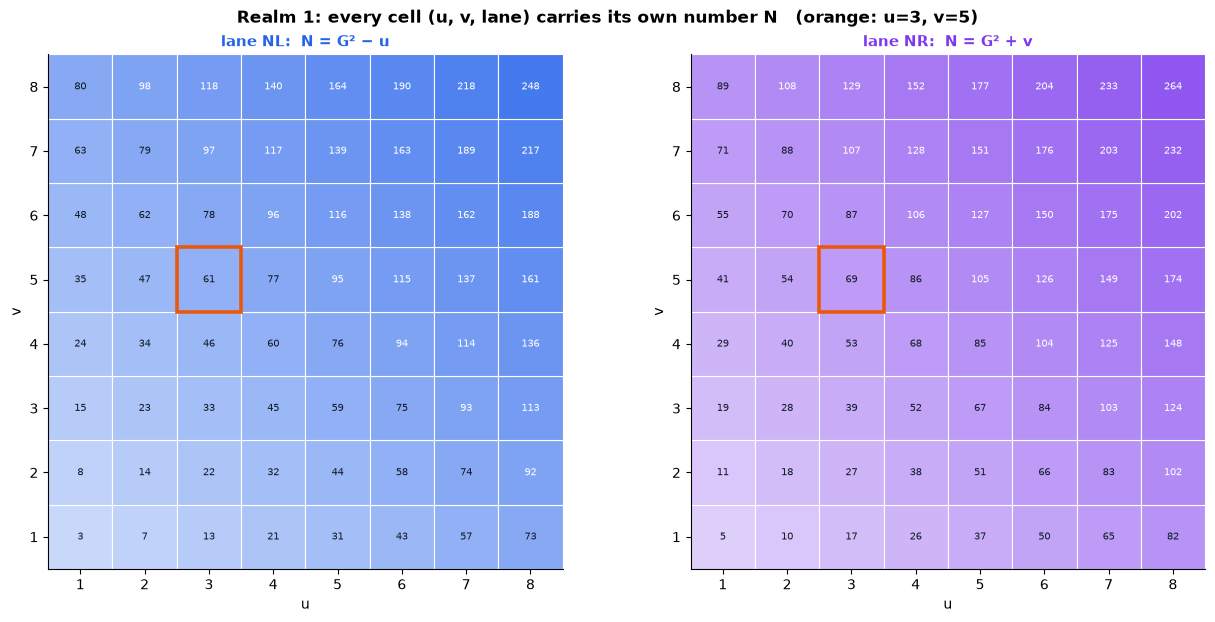

128 cells, 128 different numbers


In [3]:
U_MAX, V_MAX = 8, 8
fig, axes = plt.subplots(1, 2, figsize=(13, 6.2))
for ax, lane in zip(axes, ("NL", "NR")):
    plot_address_grid(ax, U_MAX, V_MAX, lane, highlight={(3, 5)})
fig.suptitle("Realm 1: every cell (u, v, lane) carries its own number N   (orange: u=3, v=5)",
             fontweight="bold")
plt.tight_layout()
plt.show()

numbers = [nhydb.dynadron_n(1, u, v, lane) for lane in ("NL", "NR")
           for u in range(1, U_MAX + 1) for v in range(1, V_MAX + 1)]
print(f"{len(numbers)} cells, {len(set(numbers))} different numbers")
assert len(numbers) == len(set(numbers))

**What happened?**

* Along each diagonal (one group `G`) the numbers lie right next to each other: on NL they
  **fall** by one per step in `u`, on NR they **rise** by one per step in `v`.
* The orange cell `(3, 5)` has `G = 8`, so `N = 64 − 3 = 61` on NL and `N = 64 + 5 = 69` on NR.
* 128 cells, 128 different numbers. That is no accident – the next section shows why it can
  never happen that two cells share a number.

## 3 · The staircase of all natural numbers

**Question:** Which natural numbers are cells – and what about the others?

**Minimal explanation:** sort all natural numbers into rows, one row per group `G`. Row `G`
starts at `G·(G−1)` and ends just before `G·(G+1)`. Inside each row the square `G²` sits in the
middle. Now place every number at the horizontal position `N − G²`:

* left of the square: the NL cells at position `−u`,
* right of the square: the NR cells at position `+v`,
* the square itself `G²` (**GZ**, red) and the row start `G·(G−1)` (**N0**, grey) are
  **boundary points** – they are not storage cells.

▶ **See it:**

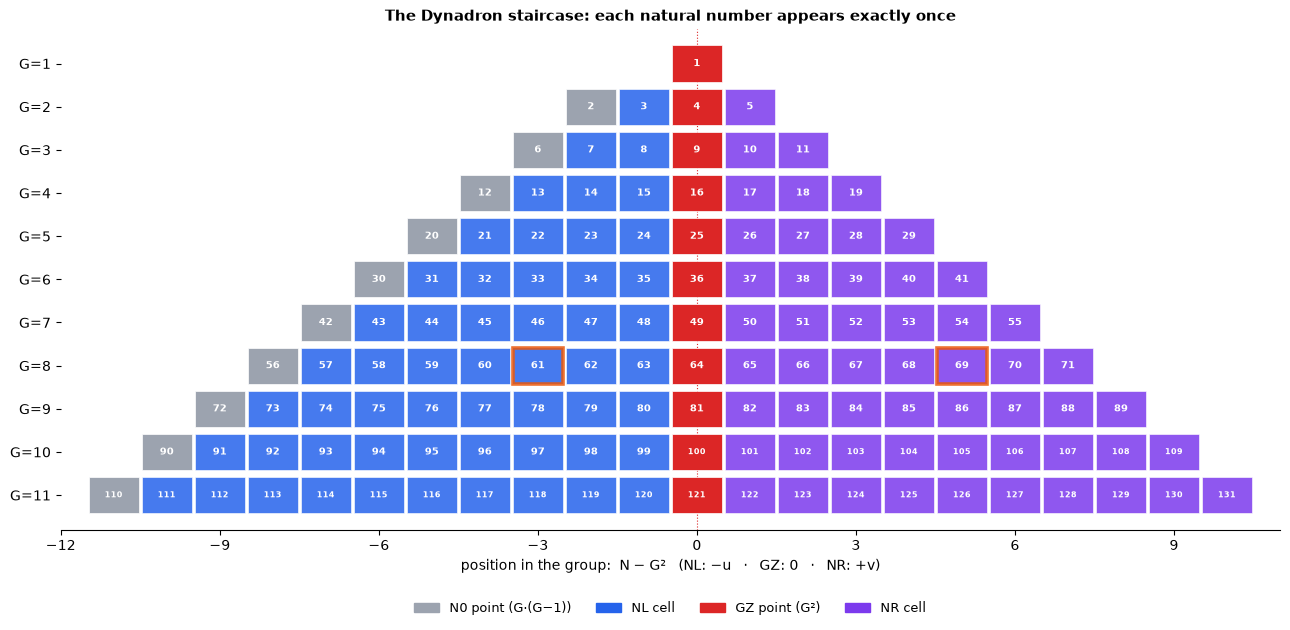

In [4]:
fig, ax = plt.subplots(figsize=(13, 6.4))
plot_staircase(ax, g_max=11, highlight={61, 69},
               title="The Dynadron staircase: each natural number appears exactly once")
plt.tight_layout()
plt.show()

**What happened? – the key idea of NHyDB**

* Read the staircase like a book, row by row, left to right: you see `1, 2, 3, 4, …` **without a
  gap and without a repetition**. Each row continues exactly where the previous one stopped.
* Every row `G` has the same structure: `N0(G)`, then `G − 1` NL cells, then `GZ = G²`, then
  `G − 1` NR cells.
* The left half of a row *is* the `u` axis (NL cell at `−u`), the right half *is* the `v` axis
  (NR cell at `+v`). The cells 61 and 69 from the grid above appear in row `G = 8` at the
  positions `−3` and `+5`.

So the numbering cannot collide: a number belongs to exactly one row, and inside its row to
exactly one position. **Ah – the address *is* the identity.**

▶ **Run it** – the structure of one row, `G = 24` (the row of our example 565 / 589):

In [5]:
G = 24
row = list(range(G * (G - 1), G * (G + 1)))
kinds = [kind_of(n) for n in row]
print(f"row G = {G}: {row[0]} … {row[-1]}   ({len(row)} numbers)")
print("N0:", [n for n, k in zip(row, kinds) if k == "N0"])
print("NL:", row[1], "…", row[G - 1], f"({kinds.count('NL')} cells)")
print("GZ:", [n for n, k in zip(row, kinds) if k == "GZ"])
print("NR:", row[G + 1], "…", row[-1], f"({kinds.count('NR')} cells)")
assert kinds == ["N0"] + ["NL"] * (G - 1) + ["GZ"] + ["NR"] * (G - 1)
assert 565 in row and 589 in row

row G = 24: 552 … 599   (48 numbers)
N0: [552]
NL: 553 … 575 (23 cells)
GZ: [576]
NR: 577 … 599 (23 cells)


## 4 · How many numbers are not cells?

**Question:** If GZ and N0 are not cells, do we lose many numbers?

Each row of `2G` numbers contains exactly two boundary points. The share of boundary points
therefore shrinks as the numbers grow – roughly like `2 / √N`.

▶ **See it:** the numbers 1 … 100 in reading order, and the share of boundary points up to
one million.

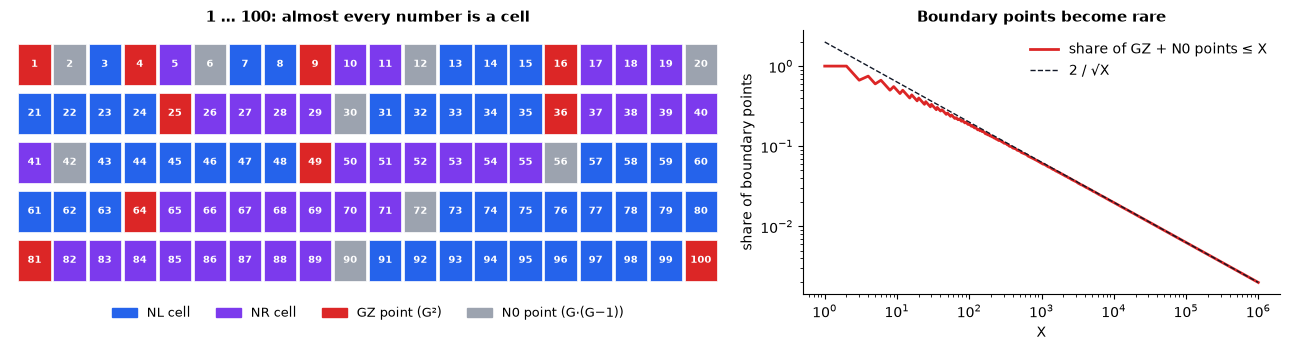

Among 1 … 10,000 there are 9801 cells and 199 boundary points.


In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1.5, 1]})
plot_number_line(ax1, 1, 101, per_row=20, title="1 … 100: almost every number is a cell")

import numpy as np
xs = np.unique(np.logspace(0, 6, 400).astype(np.int64))
# number of boundary points ≤ X: squares G² ≤ X  plus  products G(G−1) ≤ X with G ≥ 2
squares = np.floor(np.sqrt(xs))
products = np.floor((1 + np.sqrt(1 + 4 * xs)) / 2) - 1
share = (squares + products) / xs
ax2.loglog(xs, share, color=COLORS["GZ"], lw=2, label="share of GZ + N0 points ≤ X")
ax2.loglog(xs, 2 / np.sqrt(xs), color="#111827", lw=1, ls="--", label="2 / √X")
ax2.set_xlabel("X")
ax2.set_ylabel("share of boundary points")
ax2.set_title("Boundary points become rare")
ax2.legend(frameon=False)
plt.tight_layout()
plt.show()

n_cells = sum(kind_of(n) in ("NL", "NR") for n in range(1, 10_001))
print(f"Among 1 … 10,000 there are {n_cells} cells and {10_000 - n_cells} boundary points.")
assert 10_000 - n_cells == 100 + 99        # 100 squares, 99 products G(G-1) with G = 2 … 100

## 5 · Checking 200,000 numbers

**Question:** Does the engine really agree with the picture – for many numbers, not just a few?

The check below runs through every number from 1 to 200,000 (the same range the NHyDB core
test uses). For each number it asks NHyDB what the number is. For cells, it converts the number
to its address and back; for boundary points, it confirms that they are squares or products
`G·(G−1)`.

> A computer check is an illustration, not a proof. The proof is the staircase argument from
> section 3: the rows `[G(G−1), G(G+1))` cover all natural numbers without overlap, and inside a
> row every position is used once.

In [7]:
import time

LIMIT = 200_000
t0 = time.perf_counter()
counts = {"NL": 0, "NR": 0, "GZ": 0, "N0": 0}
for n in range(1, LIMIT + 1):
    try:
        a = nhydb.n_to_dynadron_address(n)
        assert nhydb.dynadron_n(a["realm"], a["u"], a["v_local"], a["lane"]) == n   # round trip
        counts[a["lane_name"]] += 1
    except nhydb.AddressError:
        g = math.isqrt(n)
        assert g * g == n or g * (g + 1) == n          # GZ = G² or N0 = G(G−1) for G = g+1
        counts["GZ" if g * g == n else "N0"] += 1
seconds = time.perf_counter() - t0

print(counts, f"– checked in {seconds:.2f} s")
assert sum(counts.values()) == LIMIT
assert counts["GZ"] == math.isqrt(LIMIT)                 # one square per group
print("Every number is exactly one cell or exactly one boundary point. ✓")

{'NL': 99681, 'NR': 99426, 'GZ': 447, 'N0': 446} – checked in 0.22 s
Every number is exactly one cell or exactly one boundary point. ✓


## 6 · The way back: from `N` to the cell

**Question:** Given only a number `N` – how do we find its cell?

**Minimal explanation:** the integer square root does all the work. Take `m = isqrt(N)` (the
largest `m` with `m² ≤ N`) and the distance `d = N − m²`:

| case | meaning | cell |
|---|---|---|
| `d = 0` | `N` is a square | **GZ** – no cell |
| `1 ≤ d < m` | just after the square `m²` | **NR**: `G = m`, `v = d`, `u = m − d` |
| `d = m` | `N = m(m+1)` | **N0** – no cell |
| `m < d ≤ 2m` | just before the next square `(m+1)²` | **NL**: `G = m + 1`, `u = G² − N`, `v = G − u` |

▶ **Run it** – a plain Python version of these four lines, compared with NHyDB:

In [8]:
import pandas as pd


def to_cell(n):
    """The inverse mapping for realm 1, written out with integers only."""
    m = math.isqrt(n)
    d = n - m * m
    if d == 0:
        return m, d, "GZ", None
    if d < m:
        return m, d, "NR", (m - d, d)                     # (u, v)
    if d == m:
        return m, d, "N0", None
    G = m + 1
    u = G * G - n
    return m, d, "NL", (u, G - u)


rows = []
for n in (589, 391, 553, 575, 576, 552, 600, 10):
    m, d, case, cell = to_cell(n)
    try:
        a = nhydb.n_to_dynadron_address(n)
        engine = f"({a['u']}, {a['v_local']}, {a['lane_name']})"
        assert cell == (a["u"], a["v_local"]) and case == a["lane_name"]
    except nhydb.AddressError as e:
        engine = "AddressError"
        assert cell is None
    rows.append({"N": n, "m = isqrt(N)": m, "d = N − m²": d, "case": case,
                 "our cell (u, v)": cell or "–", "NHyDB": engine})
pd.DataFrame(rows).set_index("N")

,m = isqrt(N),d = N − m²,case,"our cell (u, v)",NHyDB
N,,,,,
589,24,13,NR,"(11, 13)","(11, 13, NR)"
391,19,30,NL,"(9, 11)","(9, 11, NL)"
553,23,24,NL,"(23, 1)","(23, 1, NL)"
575,23,46,NL,"(1, 23)","(1, 23, NL)"
576,24,0,GZ,–,AddressError
552,23,23,N0,–,AddressError
600,24,24,N0,–,AddressError
10,3,1,NR,"(2, 1)","(2, 1, NR)"


**What happened?** Four lines of integer arithmetic turn any number back into its address –
including numbers with hundreds of digits (notebook 07). NHyDB does exactly this internally;
it never needs a lookup table.

## 7 · ▶ Your address detector

**Change it:** choose any cell and run the cell. The cell lights up in the address plane and
in the staircase, and the number is converted back.

(u=4, v=3, NR)  →  G = 7,  N = 52  →  (u=4, v=3, NR)


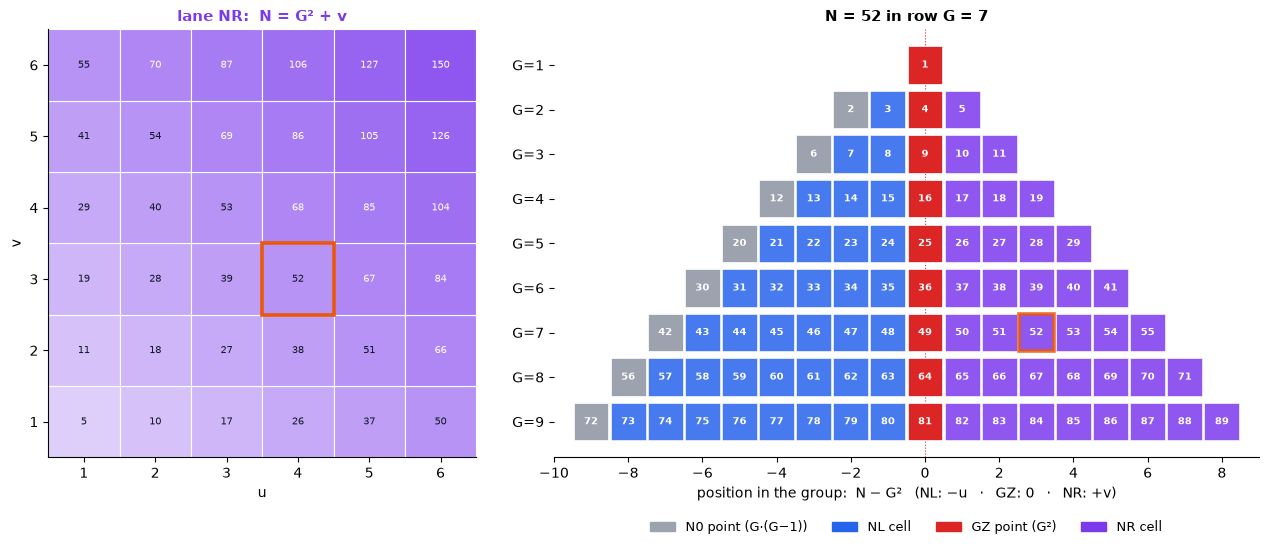

In [9]:
# ▶ Try it: change these values and re-run
U, V, LANE = 4, 3, "NR"

n = nhydb.dynadron_n(1, U, V, LANE)
back = nhydb.n_to_dynadron_address(n)
print(f"(u={U}, v={V}, {LANE})  →  G = {U + V},  N = {n}  →  "
      f"(u={back['u']}, v={back['v_local']}, {back['lane_name']})")
assert (back["u"], back["v_local"], back["lane_name"]) == (U, V, LANE)

g_show = max(U + V + 1, 9)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.6), gridspec_kw={"width_ratios": [1, 1.5]})
plot_address_grid(ax1, max(U, 6), max(V, 6), LANE, highlight={(U, V)})
plot_staircase(ax2, g_max=min(g_show, 14), highlight={n}, annotate=g_show <= 14,
               title=f"N = {n} in row G = {U + V}")
plt.tight_layout()
plt.show()

### Explore any number

`explore_n(N)` tells you what a number is, shows the full row of its group and its
neighbourhood. Try your own numbers – birthdays, phone numbers, `10**12 + 7` …

N = 589  →  NR cell
group G = 24:  N0(G) = 552 | NL 553 … 575 | GZ = 576 | NR 577 … 599 | N0(G+1) = 600
cell (R=1, u=11, v=13, NR):  G = u + v = 24,  N = G² + 13 = 576 + 13 = 589
partner on the other lane: N = 565


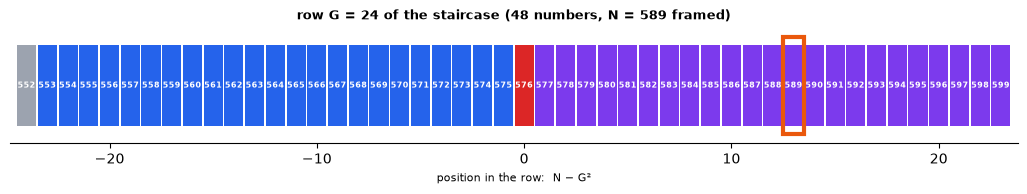

In [10]:
explore_n(589)

N = 576  →  GZ point (G²)
group G = 24:  N0(G) = 552 | NL 553 … 575 | GZ = 576 | NR 577 … 599 | N0(G+1) = 600


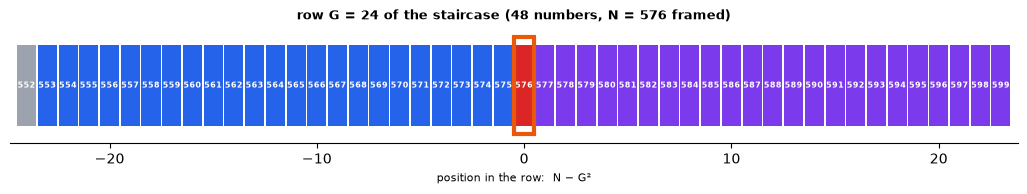

In [11]:
explore_n(576)

## 8 · Your turn

**Task 1:** Which cell is `N = 1,000,000`? Think first, then run the solution.

**Task 2:** Which numbers between 1 and 50 are *not* cells? Can you predict them without the
computer?

N = 1000000  →  GZ point (G²)
group G = 1000:  N0(G) = 999000 | NL 999001 … 999999 | GZ = 1000000 | NR 1000001 … 1000999 | N0(G+1) = 1001000


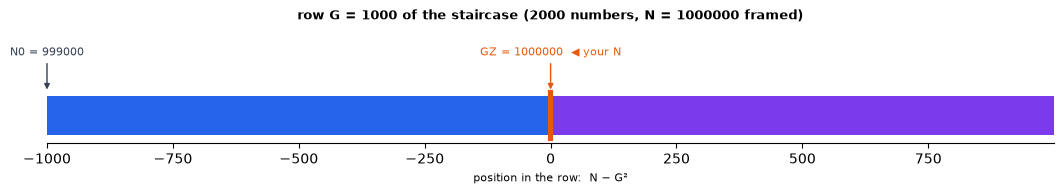

NL NR


In [12]:
# Solution 1: one million is 1000², a GZ point – it is not a cell!
explore_n(1_000_000)
assert kind_of(1_000_000) == "GZ"
# Its neighbours are cells: 999,999 is the last NL cell of G = 1000, 1,000,001 the first NR cell.
print(nhydb.n_to_dynadron_address(999_999)["lane_name"], nhydb.n_to_dynadron_address(1_000_001)["lane_name"])

In [13]:
# Solution 2: the squares G² (GZ) and the products G·(G−1) (N0).
not_cells = [n for n in range(1, 51) if kind_of(n) in ("GZ", "N0")]
predicted = sorted({g * g for g in range(1, 8)} | {g * (g - 1) for g in range(2, 8)})
predicted = [n for n in predicted if n <= 50]
print("not cells:", not_cells)
assert not_cells == predicted

not cells: [1, 2, 4, 6, 9, 12, 16, 20, 25, 30, 36, 42, 49]


## ⏩ Advanced: derived indicators

`dynadron_address(R, u, v)` returns, besides `G`, `NL` and `NR`, a few *station indicators*
(`station`, `stufe`, …). They are computed on demand and are **not** part of the cell identity –
the identity is always `(R, u, v, lane)` and its number `N`.

In [14]:
info = nhydb.dynadron_address(1, 3, 5)
{k: info[k] for k in ("realm", "u", "v", "G", "NL", "NR", "station", "stufenbreite", "stufe", "stufenstation")}

{'realm': 1,
 'u': 3,
 'v': 5,
 'G': 8,
 'NL': 61,
 'NR': 69,
 'station': 4,
 'stufenbreite': 5,
 'stufe': 1,
 'stufenstation': 4}

## Summary

* A cell `(u, v, lane)` of realm 1 has the number `N = G² − u` (NL) or `N = G² + v` (NR) with `G = u + v`.
* All natural numbers form a staircase of groups: `N0`, NL cells, `GZ`, NR cells – every number exactly once.
* Squares (GZ) and products `G(G−1)` (N0) are boundary points, not cells; they become rare quickly.
* The way back needs only `isqrt`: NHyDB never stores a table of addresses.

## Where to go next

* [02 · From Mathematics to Stored Values](02_from_address_to_data_v1.ipynb) – store real data in these cells.
* [05 · MATH_MAP](05_math_map_text_and_formula_lab_v1.ipynb) – let a formula choose the cells.
* [07 · Huge Addresses](07_realms_and_huge_numbers_v1.ipynb) – realms and numbers with hundreds of digits.
* Mathematical background (German): *Das Dynadron der natürlichen Zahlen*, doi:10.5281/zenodo.22549415.

**Cookbook sections:** 9 (Addresses and the number N), 10 (Reading by N) in the [NHyDB Python Cookbook](https://github.com/nhydb/NHyDB/blob/main/docs/cookbook/PYTHON_COOKBOOK.md).

In [15]:
# Clean up: remove the temporary folder with all databases of this notebook.
cleanup()
print("Temporary files removed.")

Temporary files removed.
